# Bloque 5. Exploración de la serie temporal, climatología y anomalías

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alvaroparedesl/geomatica-aplicada/blob/main/talleres/fair-series-temporales/05_exploracion_series.ipynb) [![Licencia: GPL-3.0](https://img.shields.io/badge/licencia-GPL--3.0-blue.svg)](https://github.com/alvaroparedesl/geomatica-aplicada/blob/main/LICENSE) [![Python 3.13](https://img.shields.io/badge/python-3.13-blue.svg)](https://colab.research.google.com/)

Taller *Datos FAIR, series temporales satelitales y detección de anomalías con Python*. Día 2, mañana (unos 85 minutos).

Partimos del parquet que guardaste ayer, sin recalcular nada: ese es el punto de tener la serie en un archivo con metadatos. Ahora toca **mirarla con números**: qué valores típicos tiene cada punto, cómo cambia en el tiempo, qué es estacional y qué es raro.

**Qué vas a hacer**

| Parte | Tema | Minutos |
|---|---|---|
| 1 | Cargar el parquet y sus metadatos | 10 |
| 2 | Estadísticos descriptivos por punto | 10 |
| 3 | Fechas irregulares y media móvil | 10 |
| 4 | Tendencia lineal, y qué puede decir un solo año | 15 |
| 5 | Patrones estacionales | 10 |
| 6 | Anomalías con un año de datos (z-score) | 15 |
| 7 | Preparando el bloque 7: climatología y anomalías con Landsat | 10 |
| 8 | Interpretación: pluma del Biobío, clorofila en la bahía y humedal | 5 |

## Preparar el entorno

La celda `Preparar entorno` clona el repositorio del curso (para usar `utils/`). Este bloque solo usa pandas, numpy, scipy, matplotlib y pyarrow, que Colab ya trae: no hay nada más que instalar.

In [1]:
# @title Preparar entorno (ejecutar primero)
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: clonar el repositorio (y actualizarlo si ya estaba)
    RAIZ = Path("/content/geomatica-aplicada")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/alvaroparedesl/geomatica-aplicada", str(RAIZ)], check=True)
    else:  # una sesión anterior ya lo clonó: traer lo nuevo para no usar código viejo
        subprocess.run(["git", "-C", str(RAIZ), "pull", "-q", "--ff-only"], check=False)
else:  # Local: subir desde la carpeta actual hasta encontrar utils/
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir())
sys.path.insert(0, str(RAIZ))
DATOS = RAIZ / "talleres" / "fair-series-temporales" / "datos"  # carpeta con los archivos de datos del taller

In [2]:
# @title Importar bibliotecas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# Funciones de apoyo del curso (carpeta utils/)
from utils.extremos import controlar_calidad_agua
from utils.series import anomalias_zscore, resumen_validez, tendencia_lineal

# Una paleta que se distingue bien con daltonismo (Okabe-Ito), un color por punto
PALETA = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]
VARIABLES = ["ndwi", "ndci", "b04", "ndvi"]
ETIQUETAS = {"ndwi": "NDWI (agua)", "ndci": "NDCI (clorofila)", "b04": "B04, reflectancia roja (turbidez)", "ndvi": "NDVI (vegetación)"}

## 1. Cargar el parquet y sus metadatos

Usamos `series_sentinel2_concepcion.parquet`, la serie de 12 meses preparada con el mismo flujo del bloque 4 (si guardaste tu propio parquet de tres meses, puedes cargarlo igual con `pd.read_parquet` y la ruta de tu archivo, pero los resultados de este cuaderno hablan de los 12 meses). Primero lo que el archivo dice de sí mismo:

In [6]:
ruta = DATOS / "mi_serie_sentinel2.conguillio.parquet"
tabla = pd.read_parquet(ruta)
# Los metadatos viajan dentro del archivo, como bytes (la clave "pandas" es de pandas y no nos interesa)
metadatos = {k.decode(): v.decode() for k, v in pq.read_schema(ruta).metadata.items() if k != b"pandas"}
print(metadatos["titulo"])
print("Fuente:", metadatos["fuente"])
print("Licencia:", metadatos["licencia"])
print(f"\n{len(tabla)} filas, {tabla['id'].nunique()} puntos, {tabla['fecha'].min():%Y-%m-%d} a {tabla['fecha'].max():%Y-%m-%d}")
tabla.head(3)

Series temporales Sentinel-2 en puntos de agua y costa de Concepción (2025-12-01 a 2026-03-31)
Fuente: ESA Copernicus Sentinel-2 L2A, leído como COG desde Microsoft Planetary Computer (colección sentinel-2-l2a)
Licencia: Datos Copernicus Sentinel de acceso libre y abierto (Reglamento UE 1159/2013). Cita: contiene datos Copernicus Sentinel modificados (2026).

255 filas, 5 puntos, 2025-12-02 a 2026-03-30


,id,nombre,tipo,lat,lon,fecha,ndwi,ndci,b04,ndvi,nubes_escena,pixeles_validos,n_pixeles,offset_reflectancia
0,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2025-12-02 14:28:11.024,NaN,NaN,NaN,NaN,89.580140,0.0,705,-0.1
1,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2025-12-03 14:37:51.025,0.127604,-0.001314,0.0337,0.015782,15.377601,1.0,705,-0.1
2,Laguna_Conguillio,Laguna Conguillio,Laguna,-38.633175,-71.642513,2025-12-05 14:27:09.024,NaN,NaN,0.0001,NaN,0.011422,1.0,705,-0.1


Recuerda que en cada punto hay fechas en las que **la ventana estaba tapada** y los índices son NaN: las fechas se conservan para que se vea el vacío. `resumen_validez` cuenta cuántas sirven. Casi todo este bloque trabaja con una serie por punto y variable. La sacamos de la tabla filtrando por punto, usando la fecha como índice y quitando los NaN: queda una `pandas.Series` con índice de fechas y **sin los NaN**.

In [7]:
resumen_validez(tabla)[["nombre", "fechas", "fechas_validas", "porcentaje_valido", "pixeles_validos_medio"]]

,nombre,fechas,fechas_validas,porcentaje_valido,pixeles_validos_medio
id,,,,,
Laguna_Conguillio,Laguna Conguillio,51,32,63.0,0.70
Laguna_Verde,Laguna verde,51,33,65.0,0.70
Malipeuco,Malipeuco,51,37,73.0,0.72
Río_Trufu_Truful,Rio Trufu Truful,51,35,69.0,0.69
Volcan_Pichi_Llaima,Volcan Pichi Llaima,51,37,73.0,0.71


In [8]:
pluma_b04 = tabla[tabla["id"] == "biobio_pluma"].set_index("fecha")["b04"].dropna()
print(type(pluma_b04).__name__, len(pluma_b04), "valores")
pluma_b04.head(4)

Series 0 valores


,b04
fecha,


## 2. Estadísticos descriptivos por punto

Media, mediana y percentiles. Con series ambientales conviene mirar siempre más de un número, porque los valores extremos (una nube que se coló, un evento real) tiran de la media pero casi no mueven la mediana.

In [9]:
def resumen_variable(variable):
    """Estadísticos descriptivos de una variable, un punto por fila."""
    grupo = tabla.groupby("id", sort=False)[variable]
    return pd.DataFrame({
        "n": grupo.count(), "media": grupo.mean(), "mediana": grupo.median(),
        "p10": grupo.quantile(0.10), "p90": grupo.quantile(0.90), "desv": grupo.std(), "min": grupo.min(), "max": grupo.max(),
    }).round(3)


print("B04 (reflectancia roja)")
resumen_variable("b04")

B04 (reflectancia roja)


,n,media,mediana,p10,p90,desv,min,max
id,,,,,,,,
Laguna_Conguillio,36,0.010,0.005,0.000,0.029,0.015,0.000,0.075
Laguna_Verde,35,0.017,0.008,0.002,0.047,0.019,0.000,0.068
Malipeuco,37,0.085,0.085,0.063,0.108,0.018,0.045,0.121
Río_Trufu_Truful,35,0.047,0.045,0.038,0.054,0.007,0.031,0.057
Volcan_Pichi_Llaima,37,0.277,0.129,0.049,0.673,0.260,0.039,0.835


Fíjate en el golfo de Arauco y en la bahía de Concepción: el máximo de B04 es mucho mayor que su p90 y la media queda por encima de la mediana. Son pocas fechas que se alejan mucho. Más adelante vemos si son turbidez real o un artefacto. Veamos las cuatro variables a la vez con cajas (la caja es del p25 al p75, la línea es la mediana):

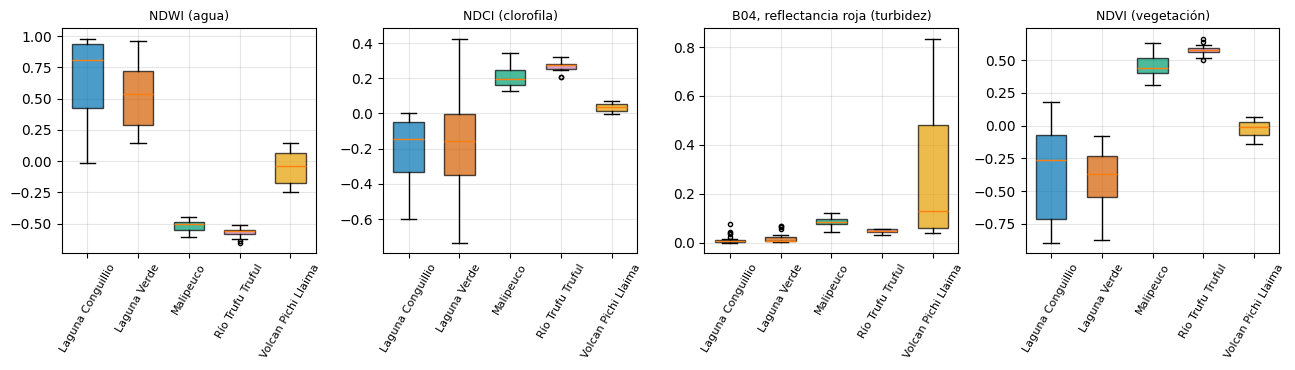

In [10]:
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.8))
orden = list(tabla["id"].unique())
for eje, variable in zip(ejes, VARIABLES):
    datos = [tabla.loc[tabla["id"] == punto, variable].dropna() for punto in orden]
    caja = eje.boxplot(datos, tick_labels=[punto.replace("_", " ") for punto in orden], patch_artist=True, widths=0.6,
                       flierprops={"markersize": 3})
    for parche, color in zip(caja["boxes"], PALETA):
        parche.set_facecolor(color)
        parche.set_alpha(0.7)
    eje.set_title(ETIQUETAS[variable], fontsize=9)
    eje.tick_params(axis="x", rotation=60, labelsize=8)
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Tu turno 1.** Haz la tabla `resumen_variable("ndci")` y `resumen_variable("ndvi")`. ¿Qué punto tiene la mediana de NDCI más alta? ¿Qué punto tiene la mayor distancia entre p10 y p90 en NDWI? ¿Por qué el NDVI y el NDWI del humedal no se parecen al de los demás puntos?

In [11]:
# Tu turno 1
resumen_variable("ndci")

,n,media,mediana,p10,p90,desv,min,max
id,,,,,,,,
Laguna_Conguillio,33,-0.195,-0.148,-0.435,-0.012,0.173,-0.600,0.003
Laguna_Verde,35,-0.178,-0.155,-0.508,0.066,0.264,-0.733,0.426
Malipeuco,37,0.211,0.197,0.143,0.285,0.057,0.128,0.341
Río_Trufu_Truful,35,0.269,0.273,0.245,0.302,0.025,0.207,0.323
Volcan_Pichi_Llaima,37,0.035,0.035,0.007,0.064,0.023,-0.002,0.072


## 3. Fechas irregulares y media móvil

Una serie de Sentinel-2 **no es diaria ni regular**. Hay más fechas útiles en verano (menos nubes) que en invierno. Mira cuántas fechas distintas hay por mes (considerando las seis ubicaciones):

In [12]:
fechas_mes = tabla.groupby(tabla["fecha"].dt.to_period("M"))["fecha"].nunique()
validas_mes = tabla.dropna(subset=["ndwi"]).groupby(tabla["fecha"].dt.to_period("M")).size() / tabla["id"].nunique()
cuenta = pd.DataFrame({"fechas con imagen": fechas_mes, "observaciones válidas por punto (promedio)": validas_mes.round(1)})
cuenta

,fechas con imagen,observaciones válidas por punto (promedio)
fecha,,
2025-12,14,7.6
2026-01,12,11.2
2026-02,12,7.8
2026-03,13,8.2


En junio, julio y agosto hay la mitad de fechas que en verano, y bastantes de ellas con la ventana tapada. Eso afecta a **todo** lo que calculemos: un promedio de invierno se apoya en pocos datos.

La **media móvil** suaviza el ruido para ver el comportamiento de fondo. `rolling` de pandas acepta una ventana en **días** (`"30D"`, adecuada para fechas irregulares) o en **observaciones** (un número entero); `min_periods` es el mínimo de observaciones que debe haber en la ventana para calcular la media y `center=True` centra la ventana en cada fecha. Compara las dos en la turbidez de la pluma del Biobío:

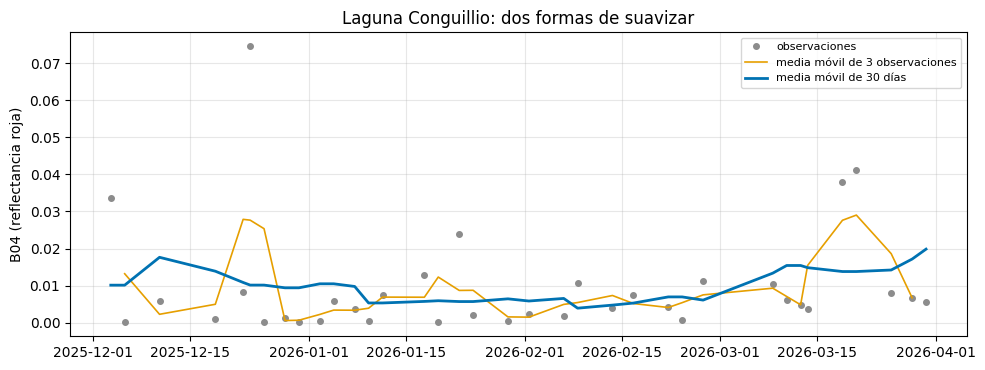

In [14]:
serie_pluma = tabla[tabla["id"] == "Laguna_Conguillio"].set_index("fecha")["b04"].dropna()
movil_30d = serie_pluma.rolling("30D", min_periods=3, center=True).mean()  # ventana de 30 días de calendario
movil_3 = serie_pluma.rolling(3, min_periods=3, center=True).mean()  # ventana de 3 observaciones

fig, eje = plt.subplots(figsize=(10, 3.8))
eje.plot(serie_pluma.index, serie_pluma, "o", markersize=4, color="0.55", label="observaciones")
eje.plot(movil_3.index, movil_3, color="#E69F00", linewidth=1.2, label="media móvil de 3 observaciones")
eje.plot(movil_30d.index, movil_30d, color="#0072B2", linewidth=2, label="media móvil de 30 días")
eje.set_ylabel("B04 (reflectancia roja)")
eje.set_title("Laguna Conguillio: dos formas de suavizar")
eje.legend(fontsize=8)
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La de 3 observaciones cubre **intervalos de tiempo distintos**: pocos días en verano y más de un mes en invierno. La de 30 días mide siempre lo mismo, pero no tiene valor donde hay menos de 3 observaciones en la ventana (por eso `min_periods=3`: es mejor un hueco que un promedio de un solo dato). Con fechas irregulares, conviene la ventana en días.

**Tu turno 2.** Prueba `"15D"` y `"60D"` con `min_periods=2`. ¿Qué pasa con los picos de B04 (en noviembre y en agosto-septiembre) al ensanchar la ventana? ¿Y con los huecos de invierno?

In [ ]:
# Tu turno 2
# movil_15d = serie_pluma.rolling("15D", min_periods=2, center=True).mean()
# movil_60d = serie_pluma.rolling("60D", min_periods=2, center=True).mean()

## 4. Tendencia lineal, y qué puede decir un solo año

`tendencia_lineal` ajusta una recta por mínimos cuadrados contra el tiempo y entrega la pendiente **por año**, el R², el valor p y la recta ajustada. Calculamos la de cada punto y variable:

In [15]:
filas = []
for id_punto in tabla["id"].unique():
    for variable in VARIABLES:
        tendencia = tendencia_lineal(tabla[tabla["id"] == id_punto].set_index("fecha")[variable].dropna())
        filas.append({"punto": id_punto, "variable": variable, "n": tendencia.n,
                      "pendiente_por_año": tendencia.pendiente_anual, "r2": tendencia.r2, "p": tendencia.p_valor})
tendencias = pd.DataFrame(filas)
tendencias.pivot(index="punto", columns="variable", values="pendiente_por_año").round(3)

variable,b04,ndci,ndvi,ndwi
punto,,,,
Laguna_Conguillio,0.002,-0.574,-2.169,1.371
Laguna_Verde,-0.085,-0.511,-0.148,0.370
Malipeuco,-0.073,0.041,0.128,-0.001
Río_Trufu_Truful,-0.055,0.100,0.206,-0.266
Volcan_Pichi_Llaima,-0.577,0.074,0.174,-0.397


Hay pendientes "grandes" y con valores p diminutos. Veamos la de la pluma del Biobío en NDWI. Ajustamos la recta con todo el año, y otra vez con solo los primeros seis meses (octubre a marzo) y con solo los últimos seis (abril a septiembre):

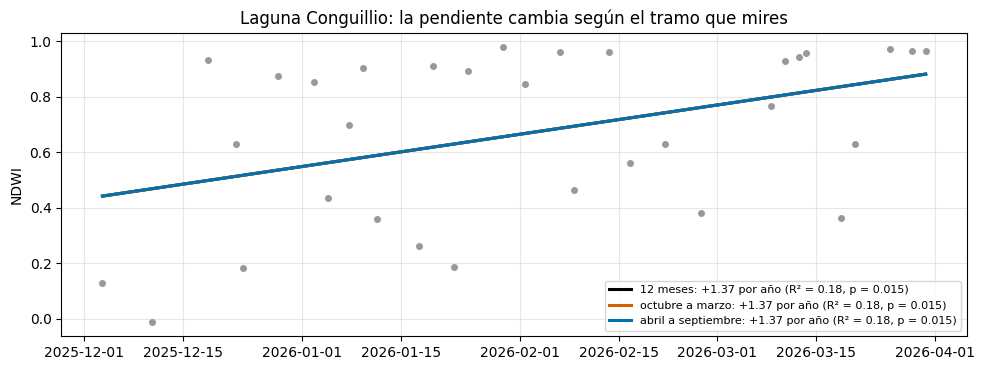

In [18]:
ndwi_pluma = tabla[tabla["id"] == "Laguna_Conguillio"].set_index("fecha")["ndwi"].dropna()
tramos = {"12 meses": ndwi_pluma, "octubre a marzo": ndwi_pluma.loc[:"2026-03-31"], "abril a septiembre": ndwi_pluma.loc["2026-04-01":]}
colores_tramos = ["#000000", "#D55E00", "#0072B2"]
fig, eje = plt.subplots(figsize=(10, 3.8))
eje.plot(ndwi_pluma.index, ndwi_pluma, "o", markersize=4, color="0.6")
for (nombre, tramo), color in zip(tramos.items(), colores_tramos):
    #tendencia = tendencia_lineal(tramo)
    eje.plot(tendencia.ajuste.index, tendencia.ajuste, color=color, linewidth=2.2,
             label=f"{nombre}: {tendencia.pendiente_anual:+.2f} por año (R² = {tendencia.r2:.2f}, p = {tendencia.p_valor:.3f})")
eje.set_ylabel("NDWI")
eje.set_title("Laguna Conguillio: la pendiente cambia según el tramo que mires")
eje.legend(fontsize=8)
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Qué puede y qué no puede decir un solo año.** La recta de los 12 meses sube; la de los últimos seis meses **baja**, y la de los primeros seis sube más. Una pendiente "por año" calculada con un año entero no es una tendencia del clima ni del ambiente: mezcla la **estacionalidad** (que sube y baja dentro del año) con cualquier cambio real, y no hay forma de separarlas con un solo ciclo. Además:

* El valor p supone observaciones independientes. En una serie temporal no lo son (un día se parece al siguiente), así que **sobreestima la significancia**. Un p de 0,0001 aquí no demuestra nada.
* Los datos no están repartidos parejo: hay muchas más fechas en verano que en invierno, y eso inclina la recta.
* Para hablar de tendencia necesitas **varios años** (idealmente décadas) y quitar antes el ciclo estacional.

La tendencia sirve aquí para describir **este año**, no para predecir. En el bloque 7 trabajamos con una serie de más de cuatro décadas, donde sí tiene sentido.

**Tu turno 3.** Calcula la pendiente de B04 en el humedal (`humedal_rocuant`) para el año completo, y para dos tramos de seis meses. ¿Cambia el signo?

In [ ]:
# Tu turno 3
# serie = tabla[tabla["id"] == "humedal_rocuant"].set_index("fecha")["b04"].dropna()
# tendencia_lineal(serie.loc[:"2026-03-31"]).pendiente_anual, tendencia_lineal(serie.loc["2026-04-01":]).pendiente_anual

## 5. Patrones estacionales

Lo que **sí** se ve con un año es el ciclo anual: cómo cambia cada variable durante los meses. Calculamos la mediana mensual de cada punto (de octubre a septiembre) y la dibujamos como mapa de calor. Fíjate en el número de observaciones que hay detrás de cada celda.

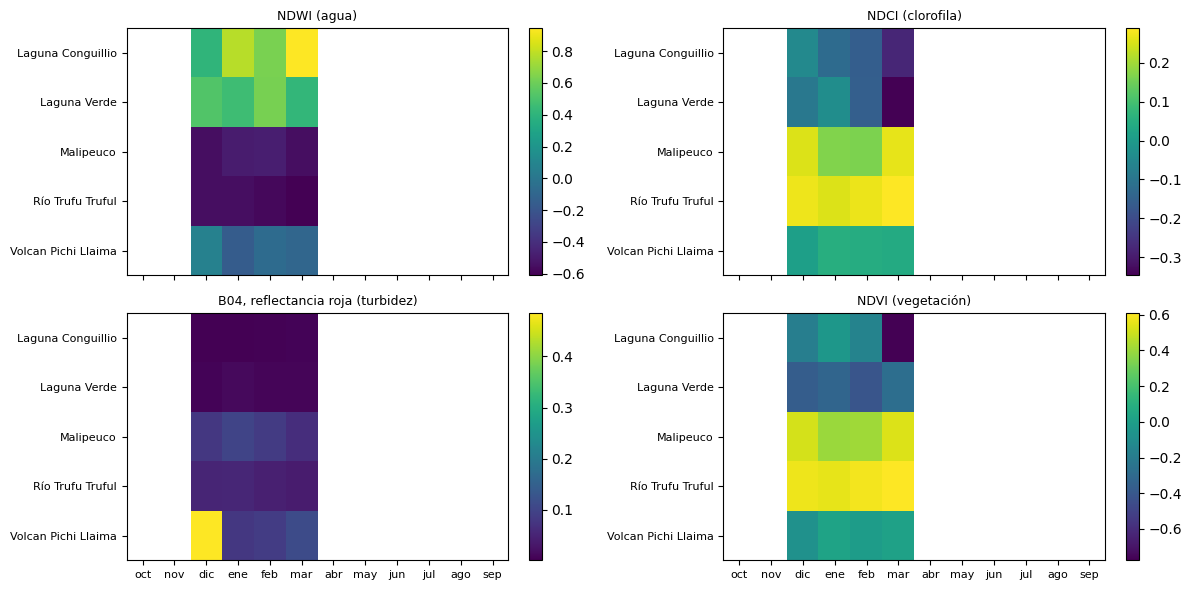

In [19]:
meses = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]
nombres_meses = ["oct", "nov", "dic", "ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep"]
fig, ejes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for eje, variable in zip(ejes.ravel(), VARIABLES):
    mediana_mes = tabla.groupby(["id", tabla["fecha"].dt.month])[variable].median().unstack().reindex(columns=meses)
    mediana_mes = mediana_mes.loc[orden]
    imagen = eje.imshow(mediana_mes.values, aspect="auto", cmap="viridis")
    eje.set_yticks(range(len(orden)), labels=[p.replace("_", " ") for p in orden], fontsize=8)
    eje.set_xticks(range(12), labels=nombres_meses, fontsize=8)
    eje.set_title(ETIQUETAS[variable], fontsize=9)
    plt.colorbar(imagen, ax=eje, fraction=0.04)
plt.tight_layout()
plt.show()

Y la climatología mensual de **un** punto: agrupamos las observaciones por mes y calculamos media, desviación y número de observaciones de cada mes. La barra de error es una desviación estándar. Mira la columna `n`.

mes        1      2      3   4   5   6   7   8   9   10  11     12
media   0.006  0.005  0.014 NaN NaN NaN NaN NaN NaN NaN NaN  0.014
desv    0.008  0.004  0.015 NaN NaN NaN NaN NaN NaN NaN NaN  0.025
n      10.000  8.000  9.000 NaN NaN NaN NaN NaN NaN NaN NaN  9.000


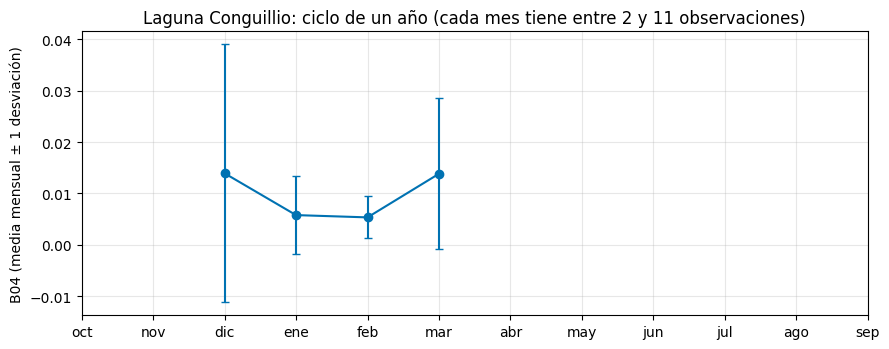

In [24]:
por_mes = serie_pluma.groupby(serie_pluma.index.month.rename("mes"))
clima_pluma = por_mes.agg(media="mean", desv="std", n="size").reindex(range(1, 13))
print(clima_pluma.round(3).T.to_string())

orden_meses = clima_pluma.reindex(meses)
fig, eje = plt.subplots(figsize=(9, 3.6))
eje.errorbar(range(12), orden_meses["media"], yerr=orden_meses["desv"], fmt="o-", color="#0072B2", capsize=3)
eje.set_xticks(range(12), labels=nombres_meses)
eje.set_ylabel("B04 (media mensual ± 1 desviación)")
eje.set_title("Laguna Conguillio: ciclo de un año (cada mes tiene entre 2 y 11 observaciones)")
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Los meses con `n` de 2 o 3 (invierno) tienen una media y una desviación que casi no significan nada. Esto es el **ciclo de un año**, no una climatología: una climatología necesita varios años (lo ideal son 30) para que cada mes tenga cientos de observaciones.

Resumamos por estación del año, que reúne más datos por grupo (en el hemisferio sur: verano de diciembre a febrero, otoño de marzo a mayo, invierno de junio a agosto y primavera de septiembre a noviembre):

In [25]:
estaciones = {12: "verano", 1: "verano", 2: "verano", 3: "otoño", 4: "otoño", 5: "otoño",
              6: "invierno", 7: "invierno", 8: "invierno", 9: "primavera", 10: "primavera", 11: "primavera"}
tabla["estacion"] = tabla["fecha"].dt.month.map(estaciones)
por_estacion = tabla.groupby(["estacion"])[["ndwi", "ndci", "b04", "ndvi"]].median().reindex(["verano", "otoño", "invierno", "primavera"])
n_estacion = tabla.dropna(subset=["b04"]).groupby("estacion").size().reindex(por_estacion.index).rename("n filas")
print("Mediana de los seis puntos juntos por estación (mezcla agua y humedal: solo para ver el ritmo)")
pd.concat([por_estacion.round(3), n_estacion], axis=1)

Mediana de los seis puntos juntos por estación (mezcla agua y humedal: solo para ver el ritmo)


,ndwi,ndci,b04,ndvi,n filas
estacion,,,,,
verano,-0.080,0.051,0.053,0.020,139.0
otoño,-0.155,0.060,0.039,0.017,41.0
invierno,NaN,NaN,NaN,NaN,NaN
primavera,NaN,NaN,NaN,NaN,NaN


**Tu turno 4.** Elige un solo punto (por ejemplo la laguna) y repite la tabla por estación solo con sus filas (`tabla[tabla["id"] == "laguna_grande"]`). ¿Qué estación tiene el NDWI más alto? ¿Y la reflectancia roja?

In [26]:
# Tu turno 4
# tabla[tabla["id"] == "laguna_grande"].groupby("estacion")[VARIABLES].median()

## 6. Anomalías con un año de datos: z-score

Una **anomalía** es un valor que se aleja de lo esperado. El z-score la mide en desviaciones estándar: `z = (valor - media) / desviación`. Un |z| mayor que 2 es poco habitual. Hay dos formas de definir "lo esperado":

* `referencia="mes"`: la media y la desviación **del mismo mes del año**. Quita el ciclo estacional (un valor de enero se compara con enero), pero necesita muchos años.
* `referencia="total"`: la media y la desviación **de toda la serie**. Mezcla estación con anomalía.

Con un año de datos, cada mes tiene entre 2 y 11 observaciones, todas del mismo año. Veamos qué pasa con B04, contando las fechas con |z| > 2 con cada referencia:

In [27]:
filas = []
for id_punto in tabla["id"].unique():
    serie = tabla[tabla["id"] == id_punto].set_index("fecha")["b04"].dropna()
    z_total = anomalias_zscore(serie, referencia="total")
    z_mes = anomalias_zscore(serie, referencia="mes")
    filas.append({"punto": id_punto, "n": len(serie), "|z| > 2 con 'total'": int((z_total.abs() > 2).sum()),
                  "|z| > 2 con 'mes'": int((z_mes.abs() > 2).sum()),
                  "z máximo 'total'": round(z_total.max(), 1), "z máximo 'mes'": round(z_mes.max(), 1)})
pd.DataFrame(filas).set_index("punto")

,n,|z| > 2 con 'total',|z| > 2 con 'mes',z máximo 'total',z máximo 'mes'
punto,,,,,
Laguna_Conguillio,36,2,2,4.3,2.4
Laguna_Verde,35,4,2,2.7,2.4
Malipeuco,37,2,0,2.0,1.8
Río_Trufu_Truful,35,1,1,1.5,1.4
Volcan_Pichi_Llaima,37,2,2,2.1,2.3


Fíjate en el golfo de Arauco: con `"total"` su valor más alto llega a un z de 8,6 y con `"mes"` solo a 2,5. Con `"mes"` ningún z pasa de unos 3 en ningún punto. No es casualidad:

* La media y la desviación de cada mes salen de **2 a 11 valores de un único año**, y el valor extremo forma parte de ese mismo mes: se "infla" su propia referencia. Con *n* valores, un z calculado así no puede pasar de (*n* - 1) / raíz(*n*); con 2 valores no pasa de 0,7. Un mes con pocos datos **no puede marcar nada**.
* Los conteos de `"mes"` casi no se parecen a los de `"total"`: miden otra cosa (cuánto se aleja un valor del resto **de su propio mes**), no cuánto se aleja de lo normal.

Con un año ninguna de las dos cuentas es una anomalía en sentido estricto. **En este bloque usamos `referencia="total"`**: es más sensible cuando la serie es corta y es simple de explicar. Su costo es que la estación se cuela: si una variable tiene un ciclo anual fuerte, los z altos tenderán a caer en la misma época (no son anomalías, es la estación). Las anomalías mensuales vienen más abajo, con una serie larga.

Calculamos el z-score de B04 en la pluma del Biobío y marcamos las fechas con |z| > 2:

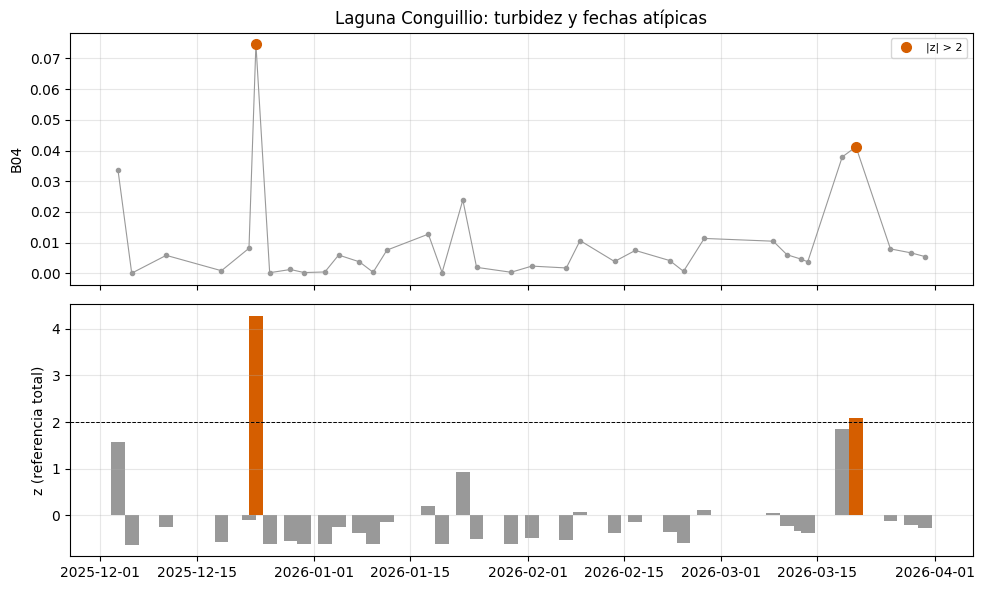

In [29]:
z_pluma = anomalias_zscore(serie_pluma, referencia="total")
raras = z_pluma[z_pluma.abs() > 2]

fig, ejes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ejes[0].plot(serie_pluma.index, serie_pluma, "o-", color="0.6", markersize=3, linewidth=0.8)
ejes[0].plot(raras.index, serie_pluma[raras.index], "o", color="#D55E00", markersize=7, label="|z| > 2")
ejes[0].set_ylabel("B04")
ejes[0].legend(fontsize=8)
ejes[1].bar(z_pluma.index, z_pluma, width=2, color=np.where(z_pluma.abs() > 2, "#D55E00", "0.6"))
ejes[1].axhline(2, color="k", linewidth=0.7, linestyle="--")
ejes[1].set_ylabel("z (referencia total)")
for eje in ejes:
    eje.grid(alpha=0.3)
ejes[0].set_title("Laguna Conguillio: turbidez y fechas atípicas")
plt.tight_layout()
plt.show()

Una fecha atípica **no es todavía un evento**. Antes de interpretar, mira qué hay detrás: ¿cuánta nube tenía la escena y qué fracción de la ventana pasó la máscara? Un valor atípico con pocos píxeles válidos o con mucha nube en la escena es sospechoso.

In [32]:
revision = tabla[(tabla["id"] == "Laguna_Conguillio") & tabla["fecha"].isin(raras.index)][["fecha", "b04", "nubes_escena", "pixeles_validos"]]
revision = revision.assign(z=raras.values)
revision.round({"b04": 3, "nubes_escena": 1, "pixeles_validos": 2, "z": 1})

,fecha,b04,nubes_escena,pixeles_validos,z
10,2025-12-23 14:37:51.025,0.075,78.0,0.7,4.3
46,2026-03-20 14:27:51.025,0.041,64.4,1.0,2.1


Y el caso más extremo de todos los puntos, el golfo de Arauco, con un z de varias unidades en B04 en una fecha de enero. La escena casi no tenía nubes y toda la ventana quedó válida. Eso **no lo explica una nube que se coló por la máscara**: hay que mirar la imagen (¿espuma, un barco, un reflejo del sol?) antes de decidir.

In [33]:
b04_golfo = tabla[tabla["id"] == "Laguna_Conguillio"].set_index("fecha")["b04"].dropna()
z_golfo = anomalias_zscore(b04_golfo, referencia="total")
fecha_max = z_golfo.idxmax()
print(f"Laguna Conguillio: B04 máximo {b04_golfo.max():.3f} el {fecha_max:%Y-%m-%d} (z = {z_golfo.max():.1f}); mediana de la serie {b04_golfo.median():.4f}")
tabla[(tabla["id"] == "Laguna_Conguillio") & (tabla["fecha"] == fecha_max)][["fecha", "b04", "ndwi", "nubes_escena", "pixeles_validos"]]

Laguna Conguillio: B04 máximo 0.075 el 2025-12-23 (z = 4.3); mediana de la serie 0.0051


,fecha,b04,ndwi,nubes_escena,pixeles_validos
10,2025-12-23 14:37:51.025,0.07455,0.183286,77.970165,0.695035


**Tu turno 5.** Calcula el z-score de NDCI en la bahía de Concepción (`bahia_concepcion`) con `referencia="total"`. ¿Cuántas fechas pasan |z| > 2? ¿Caen en una época del año en particular? Consulta `nubes_escena` y `pixeles_validos` de esas fechas.

In [ ]:
# Tu turno 5
# serie_ndci = tabla[tabla["id"] == "bahia_concepcion"].set_index("fecha")["ndci"].dropna()
# z_ndci = anomalias_zscore(serie_ndci, referencia="total")
# z_ndci[z_ndci.abs() > 2]

## 7. Preparando el bloque 7: climatología y anomalías con Landsat

Para hacer anomalías **con respecto a una climatología mensual** se necesita una serie larga. La temperatura de superficie de **Landsat 8 y 9** en el centro de la bahía de Concepción tiene datos desde **2013**: unas 10 a 25 observaciones válidas por año (Landsat pasa cada 8 días, pero las nubes borran muchas fechas). Esa es la serie con la que trabajaremos en el bloque 7.

El parquet de Landsat tiene la misma forma que el de Sentinel-2, pero con temperatura y reflectancia ya calibradas. `controlar_calidad_agua` descarta las observaciones que la reflectancia delata como nube, y la serie de un punto se saca igual que antes (aquí quitamos la hora de la toma, porque solo importa el día). Las fechas con nubes quedan como NaN: no se rellenan.

In [35]:
landsat = pd.read_parquet(DATOS / "series_landsat_concepcion.parquet")
landsat["fecha"] = landsat["fecha"].dt.normalize()
landsat = controlar_calidad_agua(landsat)
st = landsat[landsat["id"] == "bahia_concepcion"].set_index("fecha")["st_c"].astype(float)
print(f"{len(st)} pasos del satélite, {st.notna().sum()} con dato; {st.index.min():%Y-%m-%d} a {st.index.max():%Y-%m-%d}")
st.dropna().tail(3)

388 pasos del satélite, 221 con dato; 2013-03-28 a 2026-10-08


,st_c
fecha,
2026-05-25,11.224091
2026-09-06,12.434082
2026-09-14,12.939972


La climatología mensual con la base 2013 a 2024 (12 años completos) tiene **9 a 20 observaciones en cada mes**: bastante más que la de un solo año (2 a 11), pero lejos de las cientos de observaciones de una serie diaria de 30 años. Hay que tenerlo presente al interpretar.

Observaciones por mes en la base 2013-2024: 9 a 20


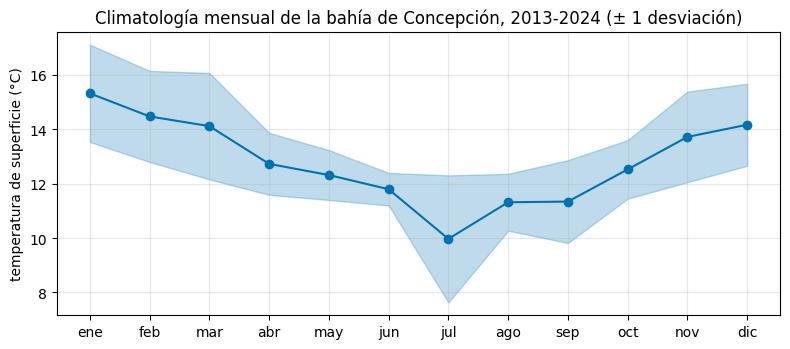

In [36]:
base = st.dropna().loc["2013":"2024"]  # los 12 años completos
clima_st = base.groupby(base.index.month.rename("mes")).agg(media="mean", desv="std", n="size").reindex(range(1, 13))
print("Observaciones por mes en la base 2013-2024:", int(clima_st["n"].min()), "a", int(clima_st["n"].max()))

fig, eje = plt.subplots(figsize=(8, 3.6))
eje.fill_between(range(1, 13), clima_st["media"] - clima_st["desv"], clima_st["media"] + clima_st["desv"], alpha=0.25, color="#0072B2")
eje.plot(range(1, 13), clima_st["media"], "o-", color="#0072B2")
eje.set_xticks(range(1, 13), labels=["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
eje.set_ylabel("temperatura de superficie (°C)")
eje.set_title("Climatología mensual de la bahía de Concepción, 2013-2024 (± 1 desviación)")
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Ahora sí funciona `referencia="mes"`: el z-score compara cada observación con el mismo mes de los 12 años de la base. Mostramos el promedio mensual de esas anomalías desde 2022. Los meses **sin barra** no tienen ninguna observación sin nubes: **un mes sin dato no es "anomalía cero"**, es un vacío.

In [ ]:
z_st = anomalias_zscore(st, referencia="mes", base=(2013, 2024))
z_mensual = z_st["2022":].resample("MS").mean()

fig, eje = plt.subplots(figsize=(11, 3.6))
eje.bar(z_mensual.index, z_mensual.fillna(0), width=25, color=np.where(z_mensual.fillna(0) >= 0, "#D55E00", "#0072B2"))
for mes in z_mensual.index[z_mensual.isna()]:
    eje.axvspan(mes, mes + pd.offsets.MonthBegin(1), color="0.85", label="mes sin observación válida")
manijas, nombres = eje.get_legend_handles_labels()
eje.legend(dict(zip(nombres, manijas)).values(), dict(zip(nombres, manijas)).keys(), fontsize=8, loc="upper left")
eje.axhline(0, color="k", linewidth=0.7)
eje.set_ylabel("anomalía mensual (z)")
eje.set_title("Temperatura de superficie en la bahía: anomalía respecto de la climatología 2013-2024")
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Anomalía media mensual reciente (z), NaN = sin observación válida:")
print(z_mensual["2026-01":].round(2).to_string())

Los meses más recientes con dato son **más fríos en mayo de 2026** (z de -0,9) y **más cálidos en septiembre de 2026** (z de +0,9). Una media mensual no es un episodio: no dice cuántas observaciones seguidas, ni si hay una nube que se coló. Con unas 1 o 2 observaciones por mes, un solo dato mueve el promedio. Eso se define con un método (umbral, observaciones seguidas, brecha máxima) y es lo que hacemos en el bloque 7 sobre esta misma serie.

**Tu turno 6.** Calcula la anomalía mensual de otro período (por ejemplo `"2014":"2017"`). ¿Hay anomalías positivas en 2015 y 2016, años de un El Niño fuerte? Cambia también la base a `(2013, 2018)` y compara cuánto cambian los z.

In [ ]:
# Tu turno 6
# z_st["2014":"2017"].resample("MS").mean().plot(kind="bar", figsize=(11, 3))

## 8. Interpretación

Volvemos a la serie de Sentinel-2 con tres preguntas. Para cada una, los números salen de los datos y la lectura es **una hipótesis**: aquí no tenemos lluvia, caudal ni mediciones de clorofila en terreno, que es lo que haría falta para confirmarlas.

**a) La pluma del Biobío.** La reflectancia roja (B04) sube con la turbidez. Comparamos la mediana mensual de la pluma con la de la bahía y el golfo:

In [ ]:
mensual_b04 = (tabla[tabla["id"].isin(["biobio_pluma", "bahia_concepcion", "golfo_arauco"])]
               .assign(mes=lambda d: d["fecha"].dt.to_period("M"))
               .pivot_table(index="mes", columns="id", values="b04", aggfunc="median"))
n_b04 = tabla.dropna(subset=["b04"]).query("id == 'biobio_pluma'").groupby(tabla["fecha"].dt.to_period("M")).size().rename("n (pluma)")
pd.concat([mensual_b04.round(3), n_b04], axis=1)

La pluma tiene una turbidez mucho mayor que el golfo y la bahía en noviembre y diciembre, y en agosto y septiembre; en otoño es casi igual a las demás. Es compatible con descargas del río (más caudal en la época de lluvias y por el deshielo de primavera), pero también podrían contribuir el viento que resuspende sedimento o el reflejo del sol. En junio y julio hay pocas fechas válidas (`n` de 2 a 3), así que esos meses no dicen mucho. Para confirmarlo harían falta la lluvia y el caudal del río (por ejemplo, de la Dirección General de Aguas).

**b) Clorofila en la bahía.** El NDCI sube con la clorofila, pero en agua muy oscura la razón es inestable. Mediana mensual en las bahías y el golfo, con el número de fechas:

In [ ]:
mensual_ndci = (tabla[tabla["id"].isin(["bahia_concepcion", "san_vicente", "golfo_arauco"])]
                .assign(mes=lambda d: d["fecha"].dt.to_period("M"))
                .pivot_table(index="mes", columns="id", values="ndci", aggfunc=["median", "count"]))
mensual_ndci.round(3)

El NDCI de la bahía de San Vicente se mantiene cerca de cero entre octubre y mayo y baja algo (hasta -0,1) de junio a septiembre. En la bahía de Concepción y el golfo de Arauco baja mucho más en invierno, pero justo ahí hay solo 2 a 6 fechas por mes y la reflectancia roja es de apenas unas milésimas (agua muy oscura): una razón entre números diminutos oscila mucho. Lo que se puede concluir es que **primavera y verano no muestran un aumento claro de clorofila en estos datos** y que el invierno es demasiado ruidoso para decidir. Comparar con clorofila medida en terreno o con un producto de color del océano sería el siguiente paso.

**c) El NDVI del humedal.** Mediana mensual del humedal Rocuant-Andalién:

In [ ]:
ndvi_humedal = tabla[tabla["id"] == "humedal_rocuant"].set_index("fecha")["ndvi"].dropna()
resumen_humedal = pd.DataFrame({"NDVI mediano": ndvi_humedal.resample("MS").median(), "n": ndvi_humedal.resample("MS").count()}).round(3)
resumen_humedal.index = resumen_humedal.index.strftime("%Y-%m")
resumen_humedal.T

El NDVI del humedal se mueve en un rango corto (de 0,5 a 0,6): es una cobertura herbácea que casi no cambia y que además tiene agua y suelo mezclados dentro del píxel. Octubre de 2025 es el mes más alto (0,62) y en otoño (marzo y abril) vuelve a subir un poco, por encima del verano. Con un solo año no podemos decir si es el ciclo normal de este humedal.

**Tu turno 7.** Elige un punto y una variable, y escribe tres frases: qué ves, qué hipótesis tienes y qué dato adicional necesitarías para confirmarla. Si trabajas en pareja, intercámbienlas y busquen una explicación alternativa.

## Cierre

* Mira siempre **más de un estadístico** (media, mediana, percentiles) y **cuántos datos** hay detrás.
* Con fechas irregulares usa ventanas en **días** y exige un mínimo de observaciones.
* Una **tendencia** de un año mezcla estación y cambio: no la uses para concluir.
* Una **anomalía** necesita una climatología con varios años; con un año usa la referencia total y desconfía de los z extremos hasta mirar la imagen.
* Un **vacío** de datos no es un cero.

En el bloque 6 hacemos estos gráficos interactivos. En el 7 usamos la serie de TSM de décadas para detectar eventos extremos.